In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")
df = pd.read_stata("Q3data.dta")
print(f"Data shape: {df.shape}")
print(f"Columns: {df.columns.tolist()}")
print(df.head())

Data shape: (27538, 6)
Columns: ['Code', 'Date', 'ROA', 'year', 'Revenue', 'Markettype']
     Code        Date       ROA  year       Revenue  Markettype
0  000070  2011-12-31  0.024539  2011  1.246863e+09         4.0
1  000070  2012-12-31  0.028659  2012  1.610088e+09         4.0
2  000070  2013-12-31  0.030341  2013  1.571950e+09         4.0
3  000070  2014-12-31  0.029131  2014  1.913255e+09         4.0
4  000070  2015-12-31 -0.086712  2015  2.449797e+09         4.0


In [8]:
#check for null values
df['ROA'] = pd.to_numeric(df['ROA'], errors='coerce')
df['Revenue'] = pd.to_numeric(df['Revenue'], errors='coerce')
df['year'] = pd.to_numeric(df['year'], errors='coerce').astype('Int64')
print(f"ROA - null values: {df['ROA'].isna().sum()}")
print(f"Revenue - null values: {df['Revenue'].isna().sum()}")
print(f"Year - null values: {df['year'].isna().sum()}")

ROA - null values: 258
Revenue - null values: 0
Year - null values: 0


In [9]:
#drop null values
df = df.dropna(subset=['Code', 'ROA', 'Revenue', 'year'])
print(f"\nAfter dropping nulls: {df.shape}")


After dropping nulls: (27280, 7)


In [11]:
#calculate the total revenue growth rate annually for 2012 - 2024
df = df.sort_values(['Code', 'year'])
df['revenue_growth'] = df.groupby('Code')['Revenue'].pct_change() * 100
print("\nRevenue Growth Statistics:")
print(df['revenue_growth'].describe())


Revenue Growth Statistics:
count    24612.000000
mean        19.634888
std        249.546768
min        -99.651331
25%         -4.361303
50%          8.198739
75%         22.453939
max      25121.124104
Name: revenue_growth, dtype: float64


In [16]:
#calculate annual median values for ROA annually for 2012 - 2024
df_analysis = df[df['year'] >= 2012].copy()
annual_medians = df_analysis.groupby('year').agg({
    'ROA': 'median',
    'revenue_growth': 'median'
}).reset_index()
print(annual_medians.to_string(index=False, float_format="%.4f"))
df_analysis['roa_above_median'] = False
df_analysis['growth_above_median'] = False
for year in df_analysis['year'].unique():
    year_roa_median = df_analysis[df_analysis['year'] == year]['ROA'].median()
    year_growth_median = df_analysis[df_analysis['year'] == year]['revenue_growth'].median()
    df_analysis.loc[df_analysis['year'] == year, 'roa_above_median'] = df_analysis.loc[df_analysis['year'] == year, 'ROA'] >= year_roa_median
    df_analysis.loc[df_analysis['year'] == year, 'growth_above_median'] = df_analysis.loc[df_analysis['year'] == year, 'revenue_growth'] >= year_growth_median

 year    ROA  revenue_growth
 2012 0.0417          6.4475
 2013 0.0372         10.7651
 2014 0.0378          8.1547
 2015 0.0372          3.4965
 2016 0.0458         11.0029
 2017 0.0518         19.2534
 2018 0.0448         11.9431
 2019 0.0440          7.4128
 2020 0.0471          4.7513
 2021 0.0480         19.4003
 2022 0.0401          4.1661
 2023 0.0352          2.7974
 2024 0.0294          2.4580


In [18]:
print("\nAbove-Median Flags (sample):")
print(df_analysis[['Code', 'year', 'ROA', 'roa_above_median', 'revenue_growth', 'growth_above_median']].head(10))
for year in [2012]:
    roa_pct = (df_analysis[df_analysis['year'] == year]['roa_above_median'].sum() /
               len(df_analysis[df_analysis['year'] == year])) * 100
    growth_pct = (df_analysis[df_analysis['year'] == year]['growth_above_median'].sum() /
                  len(df_analysis[df_analysis['year'] == year])) * 100
    print(f"\n{year} - % above median ROA: {roa_pct:.1f}%, Growth: {growth_pct:.1f}%")


Above-Median Flags (sample):
      Code  year       ROA  roa_above_median  revenue_growth  \
1   000070  2012  0.028659             False       29.131070   
2   000070  2013  0.030341             False       -2.368643   
3   000070  2014  0.029131             False       21.712179   
4   000070  2015 -0.086712             False       28.043439   
5   000070  2016  0.031458             False       88.277526   
6   000070  2017  0.045448             False       18.659544   
7   000070  2018  0.046136              True        4.255871   
8   000070  2019  0.051341              True      -24.143759   
9   000070  2020  0.006790             False        9.104383   
10  000070  2021 -0.065421             False       -2.786485   

    growth_above_median  
1                  True  
2                 False  
3                  True  
4                  True  
5                  True  
6                 False  
7                 False  
8                 False  
9                  True  
10   

In [22]:
#calculate % of firms above median ROA and revenue growth
firms_2012 = df_analysis[df_analysis['year'] == 2012]['Code'].unique()
print(f"Number of firms in 2012: {len(firms_2012)}")
years = sorted(df_analysis['year'].unique())
results = pd.DataFrame({
    'year': years,
    'roa_consistent_pct': np.nan,
    'growth_consistent_pct': np.nan,
    'roa_firms_count': np.nan,
    'growth_firms_count': np.nan,
    'total_firms': np.nan
})

for end_year in years:
    if end_year >= 2012:
        # get total firms in that year
        firms_this_year = df_analysis[df_analysis['year'] == end_year]['Code'].unique()
        results.loc[results['year'] == end_year, 'total_firms'] = len(firms_this_year)
        roa_consistent = set(firms_2012)

        for y in range(2012, end_year + 1):
            if y in df_analysis['year'].unique():
                year_firms = df_analysis[(df_analysis['year'] == y) &
                                         (df_analysis['roa_above_median'])]['Code'].unique()
                roa_consistent = roa_consistent.intersection(set(year_firms))

        results.loc[results['year'] == end_year, 'roa_consistent_pct'] = len(roa_consistent) / len(firms_2012) * 100
        results.loc[results['year'] == end_year, 'roa_firms_count'] = len(roa_consistent)
        growth_consistent = set(firms_2012)

        for y in range(2012, end_year + 1):
            if y in df_analysis['year'].unique():
                year_firms = df_analysis[(df_analysis['year'] == y) &
                                         (df_analysis['growth_above_median'])]['Code'].unique()
                growth_consistent = growth_consistent.intersection(set(year_firms))

        results.loc[results['year'] == end_year, 'growth_consistent_pct'] = len(growth_consistent) / len(firms_2012) * 100
        results.loc[results['year'] == end_year, 'growth_firms_count'] = len(growth_consistent)

print(results.to_string(index=False, float_format="%.2f"))

Number of firms in 2012: 1227
 year  roa_consistent_pct  growth_consistent_pct  roa_firms_count  growth_firms_count  total_firms
 2012               50.04                  47.27           614.00              580.00      1227.00
 2013               40.99                  27.63           503.00              339.00      1251.00
 2014               35.29                  18.34           433.00              225.00      1340.00
 2015               28.69                  12.31           352.00              151.00      1498.00
 2016               22.17                   8.39           272.00              103.00      1785.00
 2017               16.87                   4.16           207.00               51.00      2084.00
 2018               13.69                   2.53           168.00               31.00      2160.00
 2019               11.82                   1.39           145.00               17.00      2230.00
 2020               10.11                   1.14           124.00              

In [23]:
persistence = []
for year in years:
    if year > 2012 and year in df_analysis['year'].unique():
        prev_year = year - 1

        if prev_year in df_analysis['year'].unique():
            # ROA persistence from previous year
            roa_prev_firms = df_analysis[(df_analysis['year'] == prev_year) &
                                         (df_analysis['roa_above_median'])]['Code'].unique()
            roa_current_firms = df_analysis[(df_analysis['year'] == year) &
                                            (df_analysis['roa_above_median'])]['Code'].unique()

            if len(roa_prev_firms) > 0:
                roa_persist = len(set(roa_prev_firms).intersection(set(roa_current_firms)))
                roa_persist_pct = roa_persist / len(roa_prev_firms) * 100
            else:
                roa_persist = 0
                roa_persist_pct = 0

            # Growth persistence from previous year
            growth_prev_firms = df_analysis[(df_analysis['year'] == prev_year) &
                                            (df_analysis['growth_above_median'])]['Code'].unique()
            growth_current_firms = df_analysis[(df_analysis['year'] == year) &
                                               (df_analysis['growth_above_median'])]['Code'].unique()

            if len(growth_prev_firms) > 0:
                growth_persist = len(set(growth_prev_firms).intersection(set(growth_current_firms)))
                growth_persist_pct = growth_persist / len(growth_prev_firms) * 100
            else:
                growth_persist = 0
                growth_persist_pct = 0

            persistence.append({
                'year': year,
                'roa_prev_firms': len(roa_prev_firms),
                'roa_persist_count': roa_persist,
                'roa_persist_pct': roa_persist_pct,
                'growth_prev_firms': len(growth_prev_firms),
                'growth_persist_count': growth_persist,
                'growth_persist_pct': growth_persist_pct
            })

if persistence:
    persistence_df = pd.DataFrame(persistence)
    print("\nYear-over-Year Persistence:")
    print(persistence_df.to_string(index=False, float_format="%.2f"))
else:
    print("\nNo year-over-year persistence data available")
    persistence_df = pd.DataFrame()


Year-over-Year Persistence:
 year  roa_prev_firms  roa_persist_count  roa_persist_pct  growth_prev_firms  growth_persist_count  growth_persist_pct
 2013             614                503            81.92                580                   339               58.45
 2014             626                515            82.27                613                   368               60.03
 2015             670                539            80.45                626                   389               62.14
 2016             749                562            75.03                669                   404               60.39
 2017             893                674            75.48                749                   426               56.88
 2018            1042                843            80.90                893                   514               57.56
 2019            1080                882            81.67               1040                   615               59.13
 2020            11

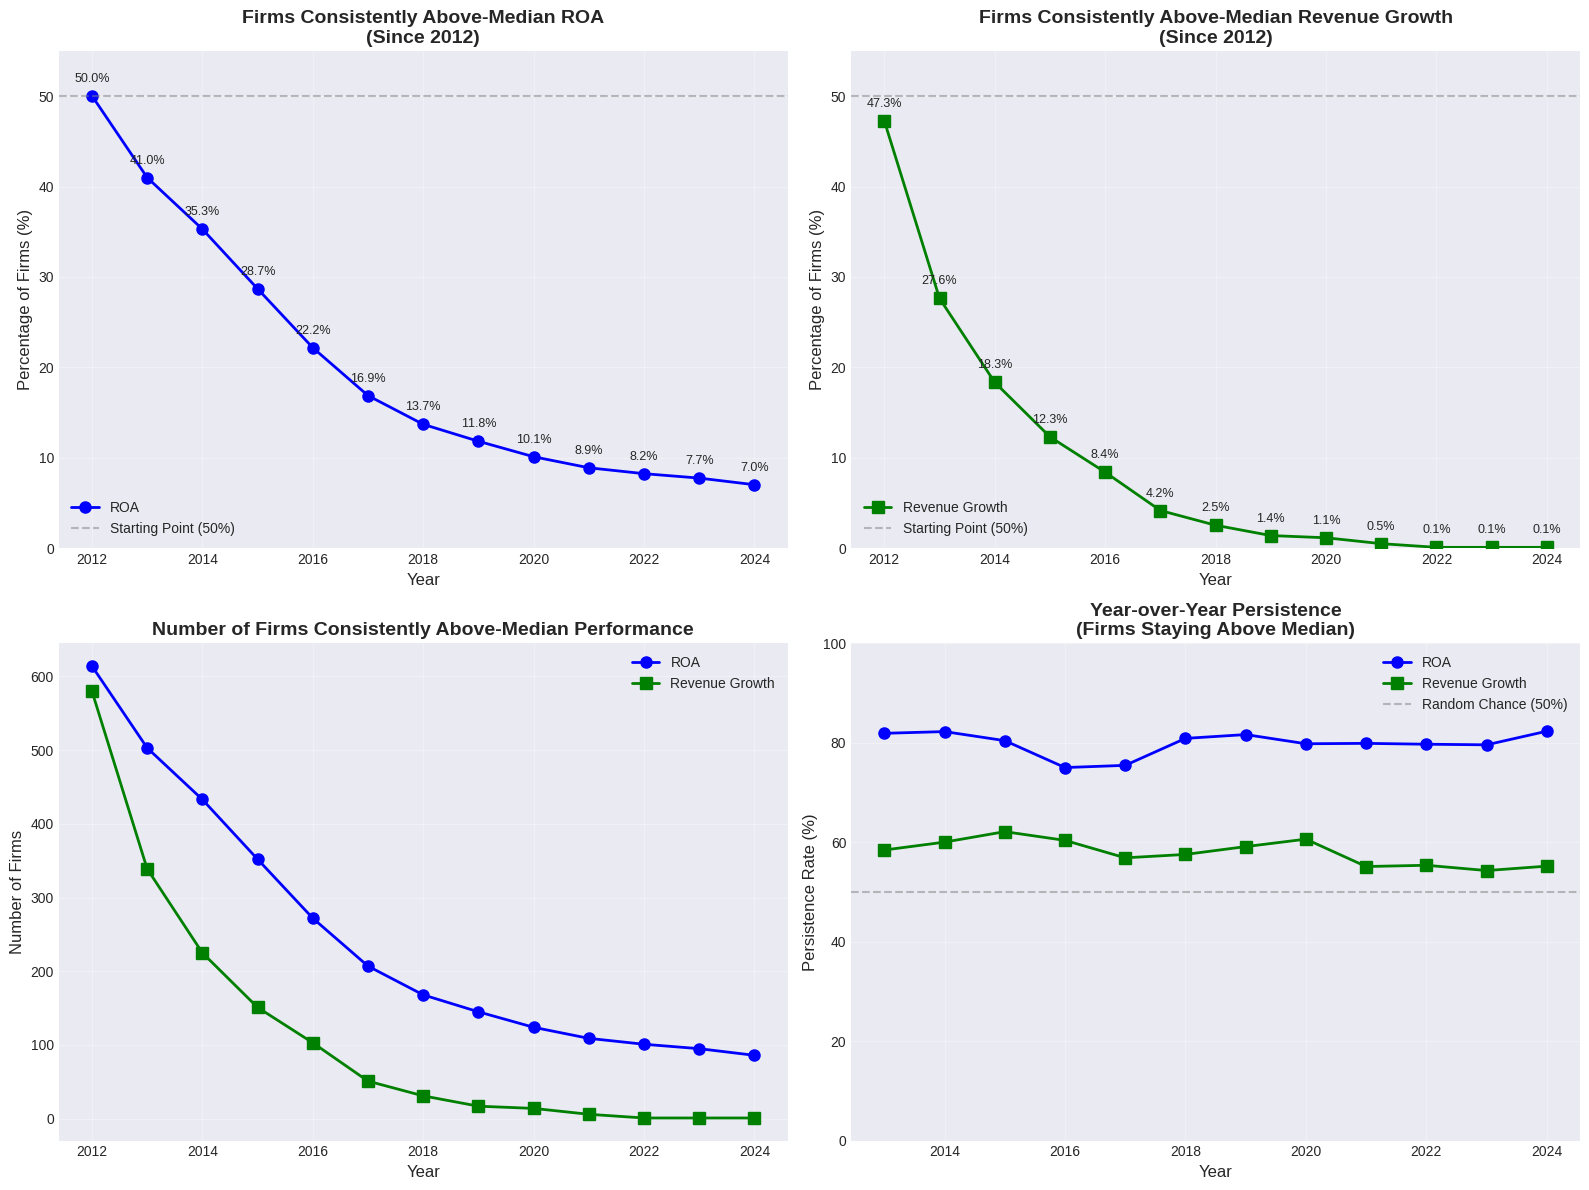

In [24]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Figure 2(a)
ax1 = axes[0, 0]
ax1.plot(results['year'], results['roa_consistent_pct'],
         marker='o', linewidth=2, markersize=8, color='blue', label='ROA')
ax1.set_xlabel('Year', fontsize=12)
ax1.set_ylabel('Percentage of Firms (%)', fontsize=12)
ax1.set_title('Firms Consistently Above-Median ROA\n(Since 2012)', fontsize=14, fontweight='bold')
ax1.grid(True, alpha=0.3)
ax1.set_ylim(0, 55)
ax1.axhline(y=50, color='gray', linestyle='--', alpha=0.5, label='Starting Point (50%)')
ax1.legend()

for i, row in results.iterrows():
    if not np.isnan(row['roa_consistent_pct']):
        ax1.annotate(f'{row["roa_consistent_pct"]:.1f}%',
                    (row['year'], row['roa_consistent_pct']),
                    textcoords="offset points", xytext=(0,10), ha='center', fontsize=9)

# Figure 2(b)
ax2 = axes[0, 1]
ax2.plot(results['year'], results['growth_consistent_pct'],
         marker='s', linewidth=2, markersize=8, color='green', label='Revenue Growth')
ax2.set_xlabel('Year', fontsize=12)
ax2.set_ylabel('Percentage of Firms (%)', fontsize=12)
ax2.set_title('Firms Consistently Above-Median Revenue Growth\n(Since 2012)', fontsize=14, fontweight='bold')
ax2.grid(True, alpha=0.3)
ax2.set_ylim(0, 55)
ax2.axhline(y=50, color='gray', linestyle='--', alpha=0.5, label='Starting Point (50%)')
ax2.legend()

for i, row in results.iterrows():
    if not np.isnan(row['growth_consistent_pct']):
        ax2.annotate(f'{row["growth_consistent_pct"]:.1f}%',
                    (row['year'], row['growth_consistent_pct']),
                    textcoords="offset points", xytext=(0,10), ha='center', fontsize=9)

# Figure 2(c)
ax3 = axes[1, 0]
ax3.plot(results['year'], results['roa_firms_count'],
         marker='o', linewidth=2, markersize=8, color='blue', label='ROA')
ax3.plot(results['year'], results['growth_firms_count'],
         marker='s', linewidth=2, markersize=8, color='green', label='Revenue Growth')
ax3.set_xlabel('Year', fontsize=12)
ax3.set_ylabel('Number of Firms', fontsize=12)
ax3.set_title('Number of Firms Consistently Above-Median Performance', fontsize=14, fontweight='bold')
ax3.grid(True, alpha=0.3)
ax3.legend()

# Figure 2(d)
ax4 = axes[1, 1]
if not persistence_df.empty:
    ax4.plot(persistence_df['year'], persistence_df['roa_persist_pct'],
             marker='o', linewidth=2, markersize=8, color='blue', label='ROA')
    ax4.plot(persistence_df['year'], persistence_df['growth_persist_pct'],
             marker='s', linewidth=2, markersize=8, color='green', label='Revenue Growth')
    ax4.set_ylim(0, 100)
    ax4.axhline(y=50, color='gray', linestyle='--', alpha=0.5, label='Random Chance (50%)')
    ax4.legend()
else:
    ax4.text(0.5, 0.5, 'No year-over-year data available',
             horizontalalignment='center', verticalalignment='center',
             transform=ax4.transAxes, fontsize=12)
ax4.set_xlabel('Year', fontsize=12)
ax4.set_ylabel('Persistence Rate (%)', fontsize=12)
ax4.set_title('Year-over-Year Persistence\n(Firms Staying Above Median)', fontsize=14, fontweight='bold')
ax4.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('persistence_analysis.png', dpi=300, bbox_inches='tight')
plt.show()

In [25]:
#calculations for analysis
print(f"ROA - Average persistence rate: {results['roa_consistent_pct'].mean():.2f}%")
print(f"ROA - Final persistence rate (2024): {results[results['year']==2024]['roa_consistent_pct'].values[0]:.2f}%")
print(f"ROA - Number of firms still above median after 13 years: {results[results['year']==2024]['roa_firms_count'].values[0]:.0f}")
print(f"\nGrowth - Average persistence rate: {results['growth_consistent_pct'].mean():.2f}%")
print(f"Growth - Final persistence rate (2024): {results[results['year']==2024]['growth_consistent_pct'].values[0]:.2f}%")
print(f"Growth - Number of firms still above median after 13 years: {results[results['year']==2024]['growth_firms_count'].values[0]:.0f}")

ROA - Average persistence rate: 20.12%
ROA - Final persistence rate (2024): 7.01%
ROA - Number of firms still above median after 13 years: 86

Growth - Average persistence rate: 9.53%
Growth - Final persistence rate (2024): 0.08%
Growth - Number of firms still above median after 13 years: 1
